# Bike-Sharing Demand Analysis & Operations Prototype

**Business question:** Riders cannot find bikes while others sit unused. Should the company buy more bikes?

**Approach:** validate the supplied data, investigate demand patterns, test one predefined hypothesis, forecast hourly recorded rentals, and provide an operations prototype with natural-language questions.

**Honest boundary:** these are completed rentals, not all desired trips or unique bikes. Without station inventories, failed rental attempts and trip durations, the exact fleet size and station redistribution cannot be identified.

Run cells top to bottom. Install the repository dependencies first (see README). All raw source files are preserved in `data/raw/`.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

ROOT = Path.cwd().resolve()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src' / 'bike_demand').exists(), 'Open this notebook from the repository.'
sys.path.insert(0, str(ROOT / 'src'))
from bike_demand.data import load_data, audit, make_features
from bike_demand.hypothesis import test_morning_share
from bike_demand.pipeline import run
from bike_demand.operations import forecast_scenario, capacity_scenario, answer_question

hour, day = load_data()
print('Hourly:', hour.shape, '| Daily:', day.shape)
display(hour.head())

Hourly: (17379, 18) | Daily: (731, 16)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,timestamp
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16,2011-01-01 00:00:00
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40,2011-01-01 01:00:00
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32,2011-01-01 02:00:00
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13,2011-01-01 03:00:00
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1,2011-01-01 04:00:00


## 1. Feature understanding and assumptions

| Field | Meaning | Treatment |
|---|---|---|
| `dteday`, `hr` | Rental date and hour | Sort time; derive calendar/cyclic features |
| `weekday`, `workingday`, `holiday` | Calendar/day type | Known in advance; 0 Sunday, 6 Saturday |
| `season`, `mnth`, `yr` | Season/month/year codes | Preserve codes; derive elapsed time from date |
| `temp`, `atemp` | Scaled air/feels-like temperature | README scales: ×41 and ×50 °C |
| `hum`, `windspeed` | Scaled humidity/wind | README scales: ×100 and ×67 |
| `weathersit` | Weather code 1–4 | Categorical; code 4 extremely sparse |
| `casual`, `registered` | Components of total rentals | Explore, but **exclude from predictors** |
| `cnt` | Total recorded rentals | Prediction target |
| `instant` | Row number | Exclude |

The README names seasons 1–4 as spring/summer/fall/winter, but actual dates map them to winter/spring/summer/autumn. We preserve numeric codes and explain the mismatch.

Daily data is used for validation and trend summaries; it is not extra independent training data. Weather is observed retrospectively; real future use requires forecast weather. No station-level or causal claims are assumed.

In [2]:
display(pd.DataFrame({
    'dtype': hour.dtypes.astype(str),
    'missing': hour.isna().sum(),
    'unique': hour.nunique()
}))
display(hour[['cnt', 'temp', 'atemp', 'hum', 'windspeed']].describe())

,dtype,missing,unique
instant,int64,0,17379
dteday,datetime64[ns],0,731
season,int64,0,4
yr,int64,0,2
mnth,int64,0,12
hr,int64,0,24
holiday,int64,0,2
weekday,int64,0,7
workingday,int64,0,2
weathersit,int64,0,4


,cnt,temp,atemp,hum,windspeed
count,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,189.463088,0.496987,0.475775,0.627229,0.190098
std,181.387599,0.192556,0.171850,0.192930,0.122340
min,1.000000,0.020000,0.000000,0.000000,0.000000
25%,40.000000,0.340000,0.333300,0.480000,0.104500
50%,142.000000,0.500000,0.484800,0.630000,0.194000
75%,281.000000,0.660000,0.621200,0.780000,0.253700
max,977.000000,1.000000,1.000000,1.000000,0.850700


## 2. Data quality

Check unique date-hour/date keys, missing cells, category/range validity, calendar consistency, non-negative counts, `cnt = casual + registered`, and per-day reconciliation of all three counts. Enumerate missing timestamps separately from missing cells.

**Policy:** do not zero-fill absent hours; do not drop extreme demand or unusual weather without evidence. Flag zero humidity. Count reconciliation establishes consistency, not why hours are absent.

In [3]:
quality, missing_hours = audit(hour, day)
display(pd.DataFrame({k: quality[k] for k in ['hour', 'day']}))
print('Missing hourly slots:', quality['missing_hour_slots'])
print('Incomplete days:', quality['incomplete_days'])
print('Daily reconciliation mismatches:', quality['daily_reconciliation_mismatches'])
display(missing_hours.head(10))

Missing hourly slots: 165
Incomplete days: 76
Daily reconciliation mismatches: 0


,hour,day
rows,17379,731.0
missing_cells,0,0.0
duplicate_keys,0,0.0
invalid_count_identity,0,0.0
negative_counts,0,0.0
invalid_scaled_weather,0,0.0
invalid_calendar,0,0.0
invalid_categories,0,0.0
total_rentals,3292679,3292679.0
invalid_hours,0,NaN


,timestamp
0,2011-01-02 05:00:00
1,2011-01-03 02:00:00
2,2011-01-03 03:00:00
3,2011-01-04 03:00:00
4,2011-01-05 03:00:00
5,2011-01-06 03:00:00
6,2011-01-07 03:00:00
7,2011-01-11 03:00:00
8,2011-01-11 04:00:00
9,2011-01-12 03:00:00


## 3. Explore demand without inspecting final-test errors

Use the development period (before July 2012) to inspect time-of-day patterns. Full-period daily trends are descriptive context, not used to tune models. Differences by weather or season are unadjusted associations and may reflect other factors.

In [4]:
development = hour[hour.dteday < '2012-07-01']
patterns = development.groupby(['hr', 'workingday']).cnt.mean().unstack()
patterns.columns = ['Non-working day', 'Working day']
ax = patterns.plot(figsize=(10, 4), color=['#e8923d', '#157a6e'])
ax.set(xlabel='Hour', ylabel='Mean recorded rentals/hour', title='Development-period hourly demand')
plt.tight_layout()
plt.show()
display(development.groupby('weathersit').cnt.agg(['count', 'mean', 'median']))

,count,mean,median
weathersit,,,
1,8595,183.441885,142.0
2,3276,151.964896,114.0
3,1129,93.919398,56.0
4,3,74.333333,36.0


## 4. One testable hypothesis

**H1:** The share of daily rentals occurring from 07:00 through 09:59 is higher on working days than on non-working days, adjusting for calendar month-year. **H0:** the adjusted difference is ≤0.

Use complete 24-hour development-period days, one observation per day. Regress morning share on working-day status and month-year fixed effects. Cluster standard errors by Monday–Sunday week; use a one-sided t-test at α=0.05 and report a two-sided 95% CI. This reduces within-week pseudo-replication but does not eliminate confounding or all time dependence. This is not a causal experiment.

In [5]:
hypothesis, hypothesis_daily = test_morning_share(hour)
display(pd.Series(hypothesis))
display(hypothesis_daily.head())

hypothesis                               Working days have a greater 07:00-09:59 share ...
null                                         The adjusted working-day coefficient is <= 0.
method                                   Daily OLS with month-year fixed effects; ISO-s...
period                                   2011-01-01 through 2012-06-30, complete 24-hou...
days                                                                                   477
week_clusters                                                                           78
workingday_mean_share                                                             0.224089
nonworking_mean_share                                                             0.072589
adjusted_difference_percentage_points                                            15.259515
ci95_percentage_points                             [14.420429150353097, 16.09860054288156]
one_sided_p_value                                                                      0.0

,dteday,total,workingday,morning,share
0,2011-01-01,985,0,25,0.025381
1,2011-01-08,959,0,44,0.045881
2,2011-01-09,822,0,35,0.042579
3,2011-01-10,1321,1,359,0.271764
4,2011-01-13,1406,1,413,0.293741


## 5. Features and experimental design

Exclude `cnt`, `casual`, `registered`, and `instant`. Use calendar, weather, elapsed days, and sine/cosine hour and annual cycles. A cyclic encoding puts 23:00 near 00:00. No lagged target features are used, avoiding recursive forecasts and unavailable within-day actuals.

| Stage | Dates | Purpose |
|---|---|---|
| Validation 1 | Jan–Feb 2012; train earlier dates | Compare fixed candidates |
| Validation 2 | Mar–Apr 2012; train earlier dates | Compare fixed candidates |
| Validation 3 | May–Jun 2012; train earlier dates | Compare fixed candidates |
| Final fit | Jan 2011–Jun 2012 | Fit selected model |
| Calibration | Jul–Aug 2012 | Estimate hourly uncertainty radius |
| Final test | Sep–Dec 2012 | Report performance once |

Candidates: recent-eight-week hour/weekday/workday mean; Ridge with one-hot categories and scaled numeric features; Poisson histogram gradient boosting. Select the lowest mean validation MAE. Settings are fixed, not an extensive search.

**Metrics:** MAE, RMSE, WAPE, R², bias; predetermined commute-hour errors and subgroup interval coverage. Evaluate against a simple baseline rather than describing regression as classification accuracy.

In [6]:
X = make_features(hour)
assert set(X).isdisjoint({'cnt', 'casual', 'registered', 'instant'})
display(X.head())
bundle, cv, test_metrics, test_predictions = run()
display(cv.round(3))
print('Selected model:', bundle['metadata']['selected_model'])

Audit and hypothesis complete
Model selection and held-out evaluation complete
             model    MAE    RMSE  WAPE_percent    R2  bias_rentals
 Calendar baseline 77.239 124.199        32.152 0.674        34.235
             Ridge 99.455 134.970        41.399 0.616        -2.507
Histogram boosting 47.985  72.907        19.974 0.888       -33.664
Saved reports to /workspace/scratch/4fd868806070/bike-sharing/reports
Selected model: Histogram boosting


,hr,weekday,mnth,season,holiday,workingday,weathersit,temp,atemp,hum,windspeed,elapsed_days,hour_sin,hour_cos,year_sin,year_cos
0,0,6,1,1,0,0,1,0.24,0.2879,0.81,0.0,0,0.000000,1.000000,0.0,1.0
1,1,6,1,1,0,0,1,0.22,0.2727,0.80,0.0,0,0.258819,0.965926,0.0,1.0
2,2,6,1,1,0,0,1,0.22,0.2727,0.80,0.0,0,0.500000,0.866025,0.0,1.0
3,3,6,1,1,0,0,1,0.24,0.2879,0.75,0.0,0,0.707107,0.707107,0.0,1.0
4,4,6,1,1,0,0,1,0.24,0.2879,0.75,0.0,0,0.866025,0.500000,0.0,1.0


,model,validation_start,validation_end_exclusive,train_rows,validation_rows,MAE,RMSE,WAPE_percent,R2,bias_rentals
0,Calendar baseline,2012-01-01,2012-03-01,8645,1433,41.212,63.648,29.546,0.750,-14.986
1,Ridge,2012-01-01,2012-03-01,8645,1433,69.090,98.081,49.533,0.406,-57.665
2,Histogram boosting,2012-01-01,2012-03-01,8645,1433,58.693,88.935,42.079,0.512,-56.098
3,Calendar baseline,2012-03-01,2012-05-01,10078,1461,96.939,141.740,41.766,0.513,-89.617
4,Ridge,2012-03-01,2012-05-01,10078,1461,92.976,131.942,40.058,0.578,-35.754
5,Histogram boosting,2012-03-01,2012-05-01,10078,1461,87.535,125.624,37.714,0.617,-84.832
6,Calendar baseline,2012-05-01,2012-07-01,11539,1464,58.118,85.735,21.341,0.846,-33.590
7,Ridge,2012-05-01,2012-07-01,11539,1464,109.174,135.204,40.088,0.616,6.743
8,Histogram boosting,2012-05-01,2012-07-01,11539,1464,38.184,58.041,14.021,0.929,-15.836


## 6. Final held-out results and uncertainty

The following results are generated from the supplied records, not hardcoded example scores. A split-calibration absolute-residual radius produces nominal 90% hourly bands. Serial dependence and seasonal drift mean 90% coverage is not guaranteed; show observed coverage. Clipping the lower bound at zero respects non-negative counts. Do not sum hourly bands to claim a calibrated daily interval.

,model,MAE,RMSE,WAPE_percent,R2,bias_rentals
0,Calendar baseline,77.239,124.199,32.152,0.674,34.235
1,Ridge,99.455,134.970,41.399,0.616,-2.507
2,Histogram boosting,47.985,72.907,19.974,0.888,-33.664


selected_model                                                        Histogram boosting
selection                              Lowest unweighted mean MAE across three expand...
training_end                                                                  2012-06-30
calibration_start                                                             2012-07-01
calibration_end                                                               2012-08-31
test_start                                                                    2012-09-01
test_end                                                                      2012-12-31
train_rows                                                                         13003
calibration_rows                                                                    1488
test_rows                                                                           2888
nominal_interval_coverage                                                            0.9
calibration_absolute_

,group,value,rows,MAE,RMSE,WAPE_percent,R2,bias_rentals,interval_coverage_percent
0,hr,0,121,18.641,34.201,27.950,0.569,-11.397,98.347
1,hr,1,120,14.243,23.488,33.481,0.684,-8.833,100.000
2,hr,2,120,8.015,14.049,29.057,0.801,-3.961,100.000
3,hr,3,117,4.947,8.692,35.339,0.686,-2.095,100.000
4,hr,4,119,3.257,4.326,38.338,-0.030,-2.472,100.000
5,hr,5,120,9.615,12.441,34.157,0.411,-7.667,100.000
6,hr,6,120,21.415,26.792,21.900,0.824,-13.823,100.000
7,hr,7,120,60.751,74.719,21.942,0.848,-38.652,89.167
8,hr,8,120,132.436,159.549,27.925,0.691,-109.128,41.667
9,hr,9,120,58.034,71.030,20.530,0.470,-40.494,90.833


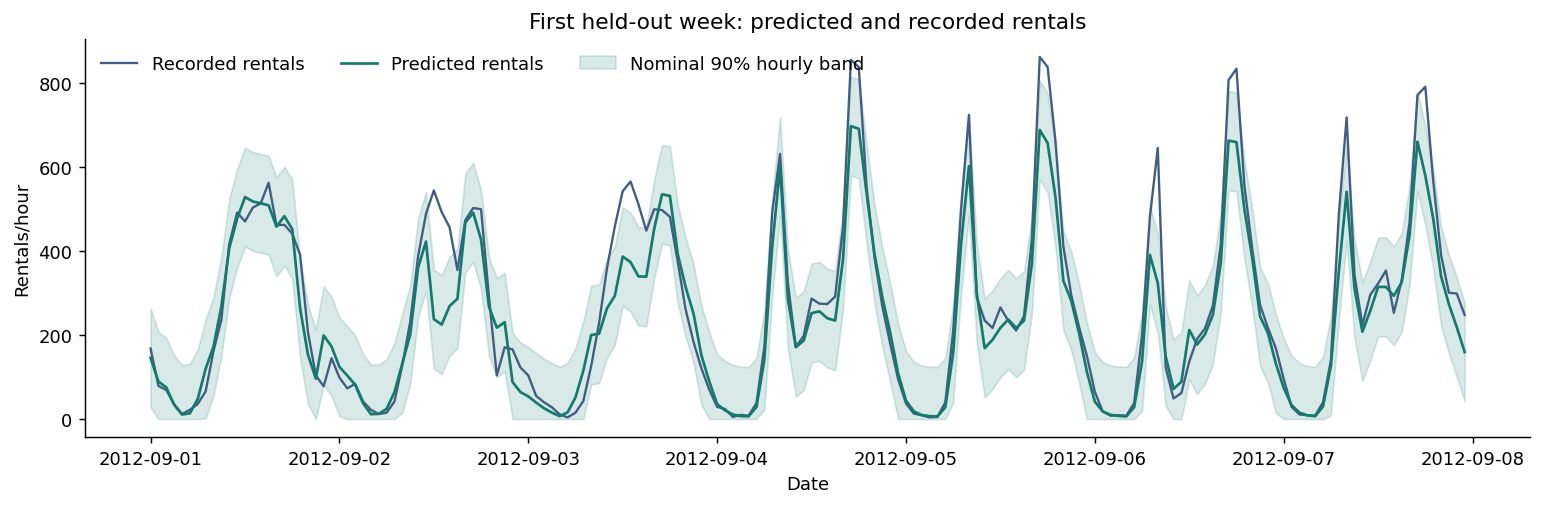

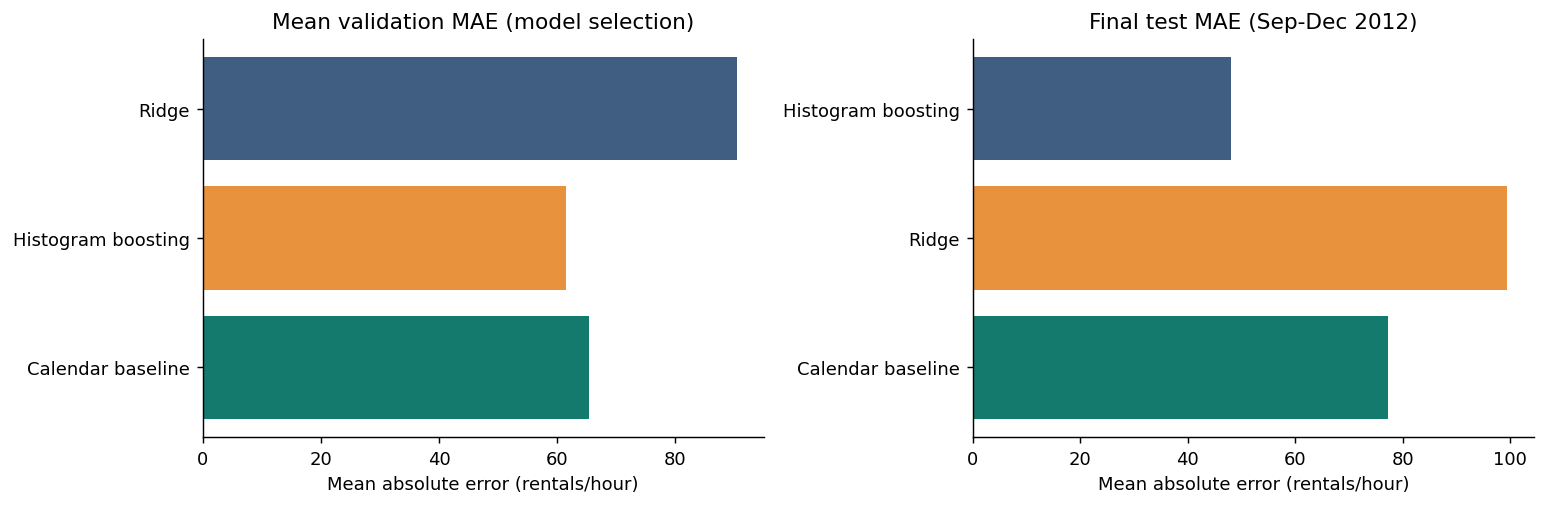

In [7]:
display(test_metrics.round(3))
display(pd.Series(bundle['metadata']))
segments = pd.read_csv(ROOT / 'reports' / 'error_segments.csv')
display(segments.round(3))
display(Image(filename=str(ROOT / 'reports' / 'figures' / 'heldout_week.png')))
display(Image(filename=str(ROOT / 'reports' / 'figures' / 'model_comparison.png')))

## 7. Interpretation and daily cross-check

Permutation importance is measured on the calibration set after model selection. Shuffling one feature can produce unusual combinations; correlated features share information. Importance is predictive association, not causality.

The daily file provides exact aggregation checks and broader trends. Daily predictions below sum the hourly model; no second daily model or duplicate activity is introduced.

,feature,MAE_increase_mean,MAE_increase_std
0,hr,175.481,1.871
1,weekday,22.835,1.697
2,workingday,17.569,0.471
3,hum,12.051,0.332
4,weathersit,2.110,0.284
5,hour_sin,1.751,0.107
6,hour_cos,0.993,0.113
7,windspeed,0.356,0.059
8,holiday,0.188,0.063
9,year_sin,0.092,0.058


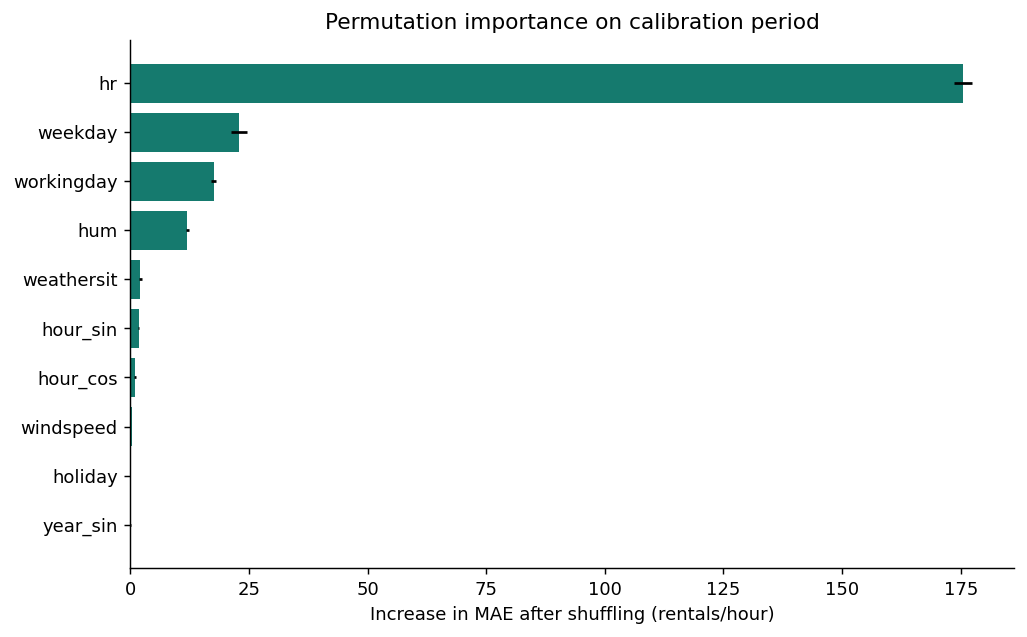

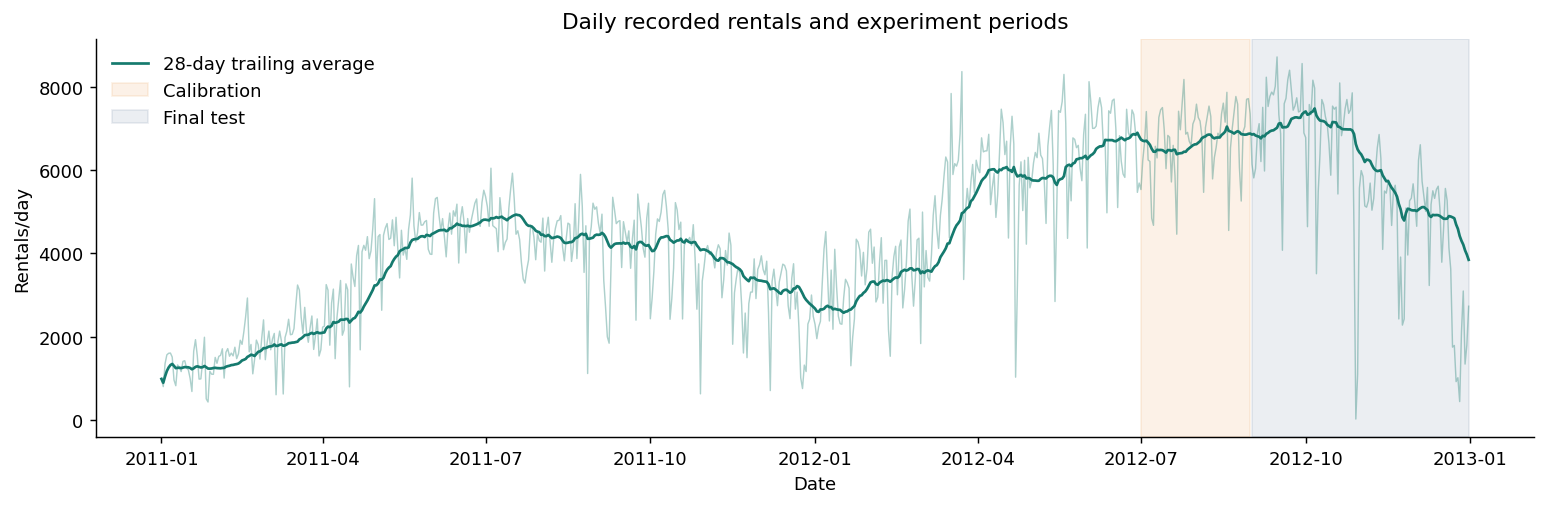

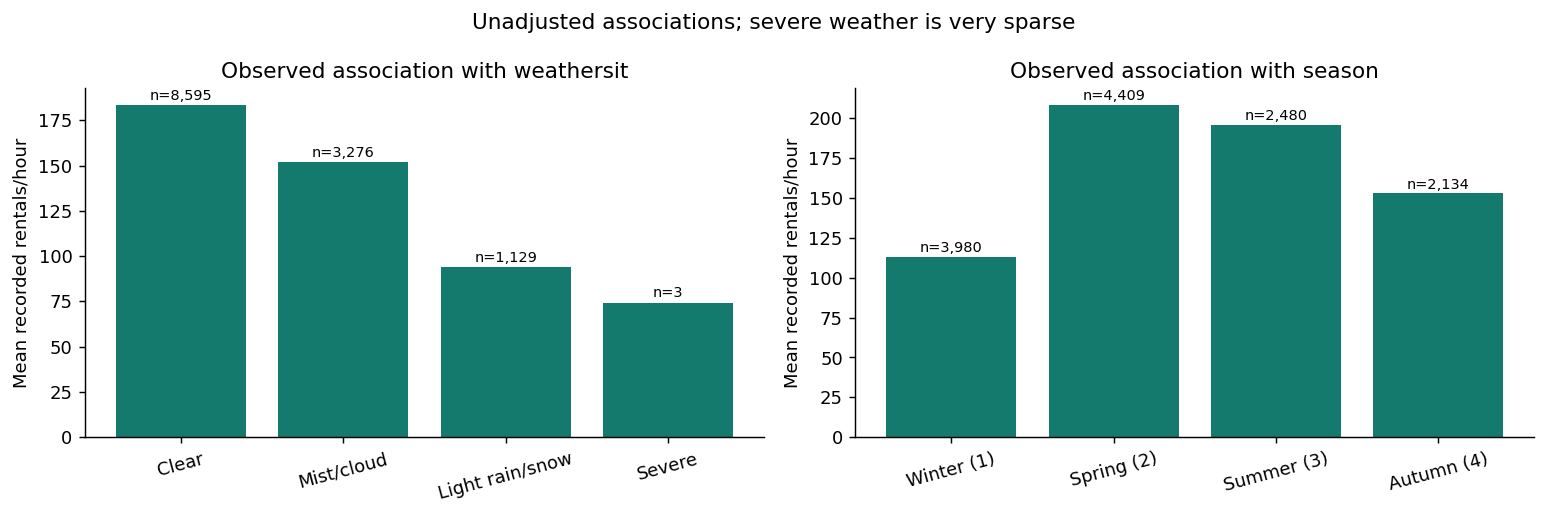

,cnt,prediction,cnt_source
dteday,,,
2012-09-01,6140,6215.523427,6140
2012-09-02,5810,4853.958394,5810
2012-09-03,6034,5446.495689,6034
2012-09-04,6864,6195.043702,6864
2012-09-05,7112,6025.289155,7112


In [8]:
display(pd.read_csv(ROOT / 'reports' / 'feature_importance.csv').round(3))
display(Image(filename=str(ROOT / 'reports' / 'figures' / 'feature_importance.png')))
display(Image(filename=str(ROOT / 'reports' / 'figures' / 'daily_trend.png')))
display(Image(filename=str(ROOT / 'reports' / 'figures' / 'weather_season.png')))
daily_predictions = test_predictions.groupby('dteday')[['cnt', 'prediction']].sum()
daily_comparison = daily_predictions.join(day.set_index('dteday')[['cnt']], rsuffix='_source')
assert daily_comparison.cnt.equals(daily_comparison.cnt_source)
display(daily_comparison.head())

## 8. Translate rental forecasts into a transparent capacity scenario

Hourly rental starts are not unique bikes. Under an explicitly assumed steady state:

**Average bicycle workload ≈ rentals/hour × (trip minutes + turnaround minutes) / 60 / usable fraction.**

Use assumptions, not invented measured values: 30-minute trips, 5-minute turnaround, 85% usable. Show sensitivity. This ignores direction, station imbalance, exact return times and lost demand, so it cannot identify how many bikes to buy. The largest hourly workload is a planning scenario, not a validated fleet requirement.

The example date is restricted to the historical holdout period. Constant weather across the day is hypothetical; air and apparent temperature are independently controllable in the app.

In [9]:
scenario = forecast_scenario(bundle, '2012-10-15', temperature_c=20,
    humidity_percent=60, windspeed=12, weather=1, holiday=False,
    apparent_temperature_c=20)
scenario['workload_bikes'] = capacity_scenario(scenario, 30, 5, .85)
display(scenario[['hr', 'prediction', 'lower_90', 'upper_90', 'workload_bikes']].round(1))
display(pd.read_csv(ROOT / 'reports' / 'capacity_sensitivity.csv'))

,hr,prediction,lower_90,upper_90,workload_bikes
0,0,46.0,0.0,163.8,32
1,1,21.4,0.0,139.2,15
2,2,10.2,0.0,128.1,8
3,3,6.7,0.0,124.5,5
4,4,6.1,0.0,123.9,5
5,5,30.0,0.0,147.8,21
6,6,138.5,20.7,256.3,96
7,7,448.2,330.3,566.0,308
8,8,593.6,475.8,711.5,408
9,9,292.5,174.7,410.3,201


,trip_minutes,turnaround_minutes,usable_fraction,largest_hourly_workload_bikes
0,15,5,0.75,394
1,15,5,0.85,347
2,15,5,0.95,311
3,30,5,0.75,689
4,30,5,0.85,608
5,30,5,0.95,544
6,45,5,0.75,983
7,45,5,0.85,868
8,45,5,0.95,777


## 9. Natural-language operations prototype

The local Streamlit app exposes date/weather controls, hourly forecasts, interval limitations, sensitivity analysis, CSV export, evidence, and plain-English questions. This implementation is a bounded intent router that calculates answers from the model and data. It has no LLM dependency or API key and does not execute user-generated code/SQL. Unsupported/ambiguous intents receive limitations.

Run from the repository terminal: `python -m streamlit run app.py`. Questions about specific stations, purchasing, or current dates are declined because required data is missing.

In [10]:
for question in ['What are the peak hours?', 'What is the daily total?',
                 'How many rentals at 8 am?', 'How many bikes under these capacity assumptions?',
                 'Should we buy more bikes?']:
    print('Q:', question)
    print('A:', answer_question(question, scenario, hour))
    print()

Q: What are the peak hours?
A: Top three hours for the 2012-10-15 weather scenario: 17:00: 771 predicted rentals; 18:00: 720 predicted rentals; 08:00: 594 predicted rentals. Counts are rental starts, not distinct bikes.

Q: What is the daily total?
A: The 2012-10-15 scenario totals 6,247 predicted rentals across 24 hours. Summed hourly counts are not unique bikes. Hourly uncertainty bands cannot be added to obtain a calibrated daily interval.

Q: How many rentals at 8 am?
A: At 08:00 on 2012-10-15: 594 predicted rentals; nominal hourly band 476-711. Temporal drift means the nominal 90% level is not guaranteed.

Q: How many bikes under these capacity assumptions?
A: Under your assumptions (30 min trip + 5 min turnaround, 85% usable; point predictions), the largest hourly workload estimate is 530 bikes. This steady-state citywide scenario is not a purchase recommendation; location imbalance and unserved riders are unmeasured.

Q: Should we buy more bikes?
A: The supplied data has citywid

## 10. Business recommendation, next experiment, and findings

Do not infer a fleet purchase from aggregate completed rentals. Use hourly forecasts to prioritize availability checks. Collect station inventory, failed searches/unlocks, trip durations/returns, and maintenance. Randomize matched station clusters to forecast-guided redistribution versus current operations; measure stockout minutes and failed attempts with cost/dock-full guardrails. Estimate sample size from pre-period variation before fixing trial length. Test additional bikes only if measured scarcity remains after redistribution.

Known limitations: two historical years, observed rather than forecast weather, no station/stockout data, missing hours of unknown cause, scarce severe weather, possible drift and underprediction, and no field validation of capacity assumptions.

The complete generated report follows.

In [11]:
display(Markdown((ROOT / 'reports' / 'findings.md').read_text()))

# Bike-sharing case study: final findings

## Recommendation to the CEO

Do not approve a fleet purchase from these aggregate counts alone. Use demand forecasts to schedule operational checks around busy periods; collect station inventory, trip duration/returns, unavailable-bike events, maintenance status, and failed rental attempts. Test redistribution at matched stations before estimating a fleet expansion's incremental value.

## What was supplied and verified

- Washington, D.C., 2011-2012: 17,379 hourly records and 731 daily records; 3,292,679 completed rentals.
- Blank cells: 0 hourly / 0 daily. Duplicate date-hour/date keys: 0 / 0.
- 165 missing hourly slots across 76 days. Missing slots remain missing; zero demand is not established.
- All rental component identities pass; hourly/daily component reconciliation mismatches: 0.
- 22 zero-humidity hourly rows flagged. No unsupported weather imputation or demand-outlier deletion.
- Daily and hourly files summarize the same activity; daily records are used for reconciliation and trends, never stacked with hourly records.
- README season labels are shifted relative to calendar dates: code 1 occurs in winter, 2 spring, 3 summer, 4 autumn. Codes are preserved; plots use calendar-consistent labels.

## Hypothesis and experimental design

Working days have a greater 07:00-09:59 share of daily rentals than non-working days, adjusting for calendar month-year.

477 complete development-period days. Daily OLS with month-year fixed effects; ISO-style Monday-Sunday week-clustered covariance; one-sided t-test, alpha=0.05; two-sided 95% confidence interval.

Unadjusted morning shares: working 22.4%, non-working 7.3%. Adjusted difference: **15.26 percentage points**, 95% CI [14.42, 16.10], one-sided p=2.05e-50.
Reject the null at alpha=0.05.
Week clustering addresses within-week dependence, not all long-range dependence. Weather, rider composition, and unobserved availability can confound this observational association. Missing-day exclusions may select days. No causal claim.

## Forecasting experiment

Three expanding training windows evaluate Jan-Feb, Mar-Apr, and May-Jun 2012. Candidates: recent-eight-week calendar mean, Ridge regression, and Poisson histogram gradient boosting. Select by mean validation MAE. Fit through June 30; calibrate uncertainty on July-August; reserve September-December for final reporting. No random train/test split or target-derived input columns.

Selected model: **Histogram boosting**. Final test MAE **47.98 rentals/hour**, RMSE 72.91, WAPE 19.97%, R² 0.888; MAE improvement over calendar baseline **37.9%**.
MAE is an average absolute count error, not an accuracy percentage. WAPE is total absolute error divided by total observed rentals.

| Model | Test MAE | Test RMSE | Test WAPE |
|---|---:|---:|---:|
| Calendar baseline | 77.24 | 124.20 | 32.15% |
| Ridge | 99.45 | 134.97 | 41.40% |
| Histogram boosting | 47.98 | 72.91 | 19.97% |

Predetermined working-day commute hours (07-09 and 16-18): MAE 104.96; nominal-band coverage 64.4%. Subgroup errors and coverage are in `error_segments.csv`.
Nominal 90% hourly intervals achieved **89.4%** test coverage; average width 206.5 rentals. Calibration radius 117.8. A nominal level is not a guarantee with seasonal/temporal drift. Do not add hourly bands to claim a calibrated daily interval.
Summed daily predictions have MAE 947.6 rentals/day. They are an aggregation of the hourly model, not a separately trained daily model.

Retrospective hourly rental estimates conditional on observed weather. Operational use needs hourly weather forecasts; forecast-weather degradation has not been measured. No lags, no target components, no station allocation. Not a 2026 production forecast.

## How to interpret feature importance

Permutation importance is measured on the calibration period after model selection, using MAE deterioration when one feature is shuffled (three repeats, seed 42). Correlated calendar/weather features share information, so this is predictive association, not a causal attribution or a promise about individual explanations.

## Bikes needed: an explicit scenario, not an identified fleet size

Hourly rental flow × (assumed trip + turnaround minutes) / 60 / assumed usable fraction estimates average citywide bicycle workload under a steady-state approximation. Round up. This is motivated by flow-times-cycle-time accounting and ignores precise returns, travel direction, start-of-hour inventory, and station imbalance. It cannot identify a fleet purchase quantity.

`capacity_sensitivity.csv` shows 15/30/45-minute trip assumptions, 5-minute turnaround, and 75/85/95% usable fractions. These inputs are assumptions, not measurements. The upper hourly rental band is an optional stress scenario; it does not turn the capacity estimate into a 90% fleet guarantee.

## Operations-manager prototype

Run `python -m streamlit run app.py`. Explore historical patterns; enter an explicitly labeled 2012 weather scenario; inspect hourly predictions/bands; vary trip-duration/reserve assumptions; download the scenario; ask supported natural-language questions about peaks, totals, an hour, historical patterns, and capacity. No API key is required. The assistant uses bounded intent routing and computed model/data answers, not an LLM. Unsupported questions receive an explicit limitation.

Scenario weather is constant across a day unless supplied programmatically. Apparent temperature defaults to air temperature as an approximation and is separately editable. Forecasts on synthetic weather combinations are not externally validated. Severe-weather category 4 has only three rows in the entire hourly file; do not trust extrapolation there.

## Proposed operational experiment

1. Instrument station stock every 5-15 minutes, trip starts/returns, maintenance, and failed searches/unlocks. Define stockout station-minutes and failed attempts as primary availability outcomes.
2. Pair comparable stations by pre-period rentals and stockouts. Randomize station clusters to forecast-guided redistribution versus current operations to reduce nearby-station spillovers. Run a pre-period, then an intervention spanning working/non-working days and weather variation.
3. Fix a practically meaningful improvement target and sample size from baseline variability; do not invent a required sample size without those measurements. Track truck distance, labor cost, dock-full minutes, and completed rentals as secondary/guardrail measures.
4. Analyze the randomized cluster-level effect with uncertainty and operational cost. Only if usable bikes remain broadly saturated after redistribution should a measured marginal fleet-expansion trial inform procurement.

## Reproduction and source

See README for setup, notebook execution, and tests. Source data and README are preserved in `data/raw/`; fingerprints and tested library versions are in `reproducibility.json`. The supplied PDF is included unchanged as `case_study.pdf`.

Dataset attribution: Hadi Fanaee-T and Joao Gama, 'Event labeling combining ensemble detectors and background knowledge', Progress in Artificial Intelligence (2013), DOI: 10.1007/s13748-013-0040-3. The supplied README requests this citation; no additional dataset license is inferred.


## Attribution

Dataset supplied with the case study. Hadi Fanaee-T and Joao Gama, *Event labeling combining ensemble detectors and background knowledge*, Progress in Artificial Intelligence (2013), DOI: 10.1007/s13748-013-0040-3. Original README and case-study PDF retained in `data/raw/`. Input fingerprints and tested dependency versions are in `reports/reproducibility.json`.